实现计算图的数据存储和自动反向传播 

In [138]:
import math
class Value:
    def __init__(self,data,_children=(),_op='',label=''):
        self.data=data
        self._pre=set(_children)
        self._op=_op
        self.label=label
        self._backward=lambda:None # 空函数
        self.grad=0
    # 打印
    def __repr__(self):
        return f"Value(data={self.data})"
    # 运算    
    def __add__(self, other):
        # if other is not Value class 可以把他变成Value类
        other = other if isinstance(other, Value) else Value(other)
        out=Value(self.data+other.data,(self,other),"+")
        def _backward():
            self.grad+=1.0*out.grad
            other.grad+=1.0*out.grad
        out._backward=_backward
        return out
    def __sub__(self, other):    
        return self + (-other)
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out=Value(self.data*other.data,(self,other),"*")
        def _backward():
            self.grad+=other.data*out.grad
            other.grad+=self.data*out.grad
        out._backward=_backward
        return out
    def __truediv__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        return self*other**(-1)
    def __pow__(self,other):
        assert isinstance(other,(int,float)),"仅支持整数或者浮点数作为指数"
        out=Value(self.data**other,(self,),"pow")
        def _backward():
            self.grad+=out.grad*other*(self.data**(other-1))
            # other.grad=out.grad*()
        out._backward=_backward
        return out
    def __neg__(self): # -x
        return self * -1
    def __rsub__(self, other):   
        return other + (-self)
    def __radd__(self, other):
        return self.__add__(Value(other))
    def __rmul__(self, other):
        return self.__mul__(Value(other))
    
    # 反向传播
    def backward(self):
        # 拓扑排序
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._pre:
                    build_topo(child)
                topo.append(v)
        build_topo(self)   
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

    # 激活函数
    def tanh(self):
        x=self.data
        t=(math.exp(x) - math.exp(-x)) / (math.exp(x) + math.exp(-x))
        out=Value(t,(self,),"tanh")
        def _backward():
            self.grad+=(1-t**2)*out.grad
        out._backward=_backward
        return out


In [139]:
from graphviz import Digraph
def trace(root):
    nodes,edges=set(),set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._pre:
                edges.add((child,v))
                build(child)
    build(root)
    return nodes,edges

def draw_dot(root):
    dot=Digraph(format='svg',graph_attr={'rankdir':"LR"})
    nodes,edges=trace(root)
    for n in nodes:
        uid=str(id(n))
        dot.node(name=uid, label="{ %s | data=%.4f | grad=%.4f }" % (n.label,n.data,n.grad), shape='record')
        if n._op:
        # 创建操作节点并连线
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
    # 标注 2 所在位置：连接 n1 到 n2 的操作节点
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot


In [140]:
a=Value(5,label='a')
b=Value(10,label='b')
c=a+b
c.label='c'
d=Value(0.1)*c
d.label='d'

e=d.tanh()
e.label='e'

e.backward()

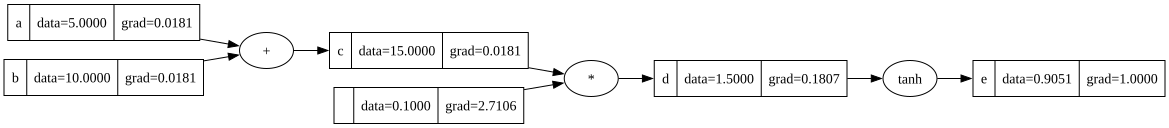

In [141]:
draw_dot(e)

梯度叠加的问题，有多个相同变量参与计算

e=(a+b)*(a+c)

In [142]:
a=Value(5,label='a')
b=Value(10,label='b')
c=Value(3,label='c')
e=(a+b)*(c+a)
e.label='e'
e.backward()

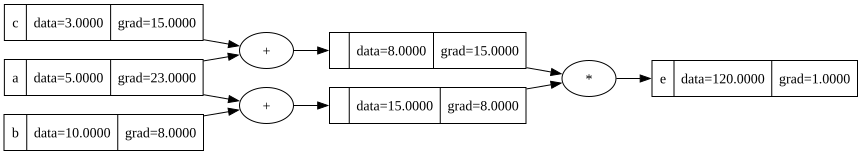

In [143]:
draw_dot(e)

上述micrograd使用的形式和属性和torch 底层的autograd类似

In [144]:
import random
class Neuron:
    """
    神经元
    """
    def __init__(self,nin):
        self.w=[Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b=Value(random.uniform(-1,1))
    def __repr__(self):
        return f'w=[{self.w}]\nb=[{self.b}]'
    def __call__(self,x):
        # 判断x是否是nin长度的list
        act=sum((wi*xi for wi,xi in zip(self.w,x)),self.b) # Value
        out=act.tanh()
        return out
    def parameters(self):
        return self.w+[self.b]

In [145]:
neuron1=Neuron(2)
neuron1([1,-1])

Value(data=0.32454982065309673)

In [146]:
class Layer:
    """
    层
    """
    def __init__(self,nin,nout):
        self.neurons=[Neuron(nin) for _ in range(nout)]
    def __call__(self, x):
        outs=[n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs
    def __repr__(self):
        return f'{self.neurons}'
    def parameters(self):
        params=[]
        for neuron in self.neurons:
            p=neuron.parameters()
            params.extend(p)
        return params

In [147]:
L1=Layer(2,1) 
l=L1([2,-2])
l

Value(data=0.7699318793621054)

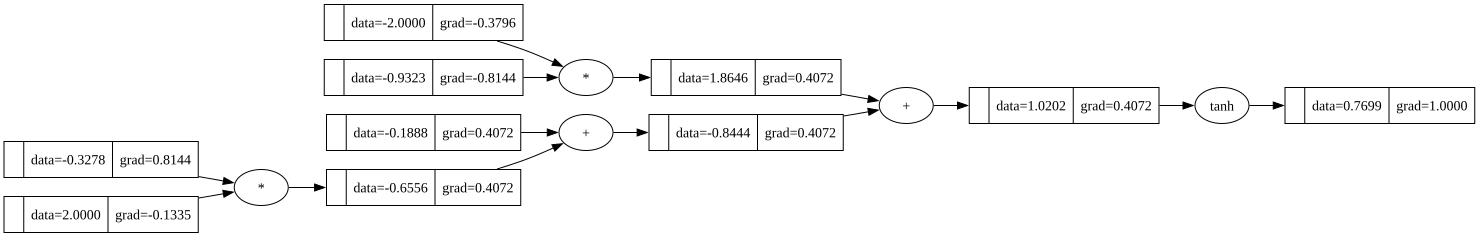

In [148]:
l.backward()
draw_dot(l)

In [149]:
class MLP:
    def __init__(self,nin,nouts):
        sz=[nin] + nouts
        self.layers=[Layer(sz[i],sz[i+1]) for i in range(len(nouts))]
    def __call__(self,x):
        for layer in self.layers:
            x=layer(x)
        return x 
    def parameters(self):
        params=[]
        for layers in self.layers:
            p=layers.parameters()
            params.extend(p)
        return params

In [150]:
net=MLP(3,[4,4,1])
net([1,-1,1])

Value(data=0.26808588723274923)

In [151]:
len(net.parameters())


41

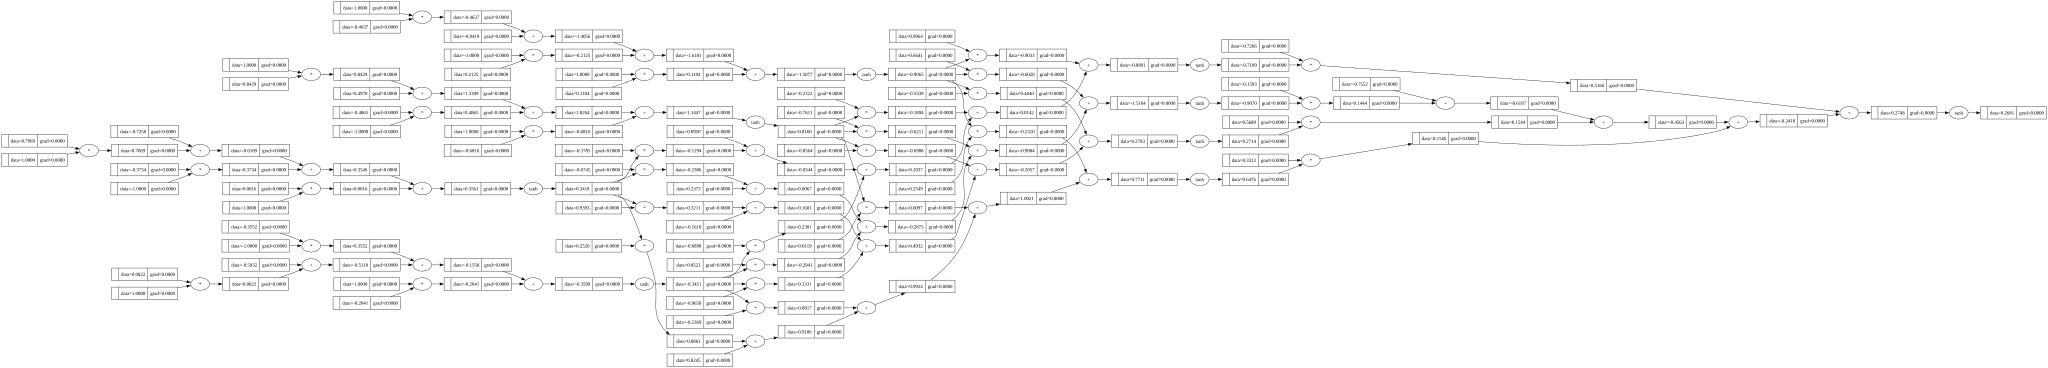

In [152]:
draw_dot(net([1,-1,1]))

MLP线性模型示例

In [153]:
net=MLP(3,[4,4,1])
x_true=[[2,3,-1],[3,-1,0.5],[0.5,1,1],[1,1,-1]]
y_true=[1,-1,-1,1]

In [154]:

# y_predict

In [155]:
# [(y1-y2)**2 for y1,y2 in zip(y_true,y_predict)]

In [175]:
y_predict=[net(x) for x in x_true]
MES_loss=sum([(y1-y2)**2 for y1,y2 in zip(y_true,y_predict)])
MES_loss.backward()

MES_loss

Value(data=0.0009755028689140087)

In [157]:
# draw_dot(MES_loss)

In [173]:
for p in net.parameters():
    print(p.data,"--",p.grad)

0.4346044298945412 -- 0.0339596760044934
-0.6045922677136999 -- 0.05854192654465835
0.6731999715458127 -- 0.02992887982409714
-0.6413250198442191 -- 0.06043228165920927
0.09724218711615121 -- -1.2779982082626975
0.007093945135210056 -- -1.860087048894841
-1.1506156661630769 -- 1.4280874005334134
0.7033619757010449 -- -0.22617127259079148
0.03603670038155893 -- 0.5465838121684338
0.24868842668563623 -- 0.749356466847079
0.2918766920938554 -- -0.6999068930188843
-0.7215641294579196 -- 0.0952474939782753
0.6466571015935264 -- -0.1326072218694374
-0.5011810701844283 -- -0.5865495927798184
1.5403028571553847 -- -1.6227136331143988
0.46486086708636043 -- -0.9620163913919209
-0.6066819936619735 -- 0.05188891249320605
-0.7291718680148453 -- -0.19655372496104978
0.3386234511847201 -- -0.13708210294360357
-0.7433202050305191 -- 0.31359051514126973
0.8027162847991323 -- 0.35068992535113935
0.18242686403224082 -- -0.4531797735519061
-0.2616302227158497 -- 0.23076245611974405
0.7330902416919072 -- 

修改parameter降低loss

In [174]:
for p in net.parameters():
    p.data-=0.1*p.grad

完整训练过程

In [ ]:
net=MLP(3,[4,4,1])
x_true=[[2,3,-1],[3,-1,0.5],[0.5,1,1],[1,1,-1]]
y_true=[1,-1,-1,1]

for e in range(50):
    y_predict=[net(x) for x in x_true]
    MES_loss=sum([(y1-y2)**2 for y1,y2 in zip(y_true,y_predict)])
    for p in net.parameters(): # zero_grad
        p.grad=0
    MES_loss.backward()
    for p in net.parameters():
        p.data-=0.1*p.grad
    print(e,"== loss:",MES_loss.data)


0 == loss: 7.159370494091861
1 == loss: 5.746114748023667
2 == loss: 2.4354467866016787
3 == loss: 0.7419661276410905
4 == loss: 0.11597481085711098
5 == loss: 0.07875084146820134
6 == loss: 0.06276698667930786
7 == loss: 0.05253198544516732
8 == loss: 0.04522267966283901
9 == loss: 0.03969155516569961
10 == loss: 0.03534491475517794
11 == loss: 0.03183432085311453
12 == loss: 0.02893847787560091
13 == loss: 0.026508891722460907
14 == loss: 0.024441737236860436
15 == loss: 0.022662040367837897
16 == loss: 0.021114222119816634
17 == loss: 0.019756169846908297
18 == loss: 0.01855537488434985
19 == loss: 0.01748633534473155
20 == loss: 0.016528762302780206
21 == loss: 0.015666312051446654
22 == loss: 0.014885672029005726
23 == loss: 0.014175890021025485
24 == loss: 0.013527874104967285
25 == loss: 0.012934014594164605
26 == loss: 0.01238789456165135
27 == loss: 0.011884065615965021
28 == loss: 0.011417872379894363
29 == loss: 0.010985313758593171
30 == loss: 0.01058293230493828
31 == loss

In [179]:
y_predict

[Value(data=0.9508582340828539),
 Value(data=-0.960052010030535),
 Value(data=-0.9634942861226313),
 Value(data=0.9713382830814605)]